# Assignment 3A – Uber Fare Prediction (Linear, Ridge, Lasso Regression)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score, mean_squared_error

## 1. Load & Pre-process

In [2]:
df = pd.read_csv('uber.csv')
df = df.drop(columns=['Unnamed: 0', 'key'], errors='ignore')
print(df.shape)
df.head(3)

(200000, 7)


,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1


In [3]:
# Drop rows with missing values and invalid fares
df = df.dropna()
df = df[df['fare_amount'] > 0]
df = df[df['passenger_count'].between(1, 6)]

# Parse datetime
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'], utc=True)
df['hour']     = df['pickup_datetime'].dt.hour
df['weekday']  = df['pickup_datetime'].dt.weekday

In [4]:
# Haversine distance (km) between pickup and dropoff
def haversine(lat1, lon1, lat2, lon2):
    R = 6371
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin(dlon/2)**2
    return R * 2 * np.arcsin(np.sqrt(a))

df['distance_km'] = haversine(
    df['pickup_latitude'],  df['pickup_longitude'],
    df['dropoff_latitude'], df['dropoff_longitude']
)

# Remove geographic outliers (NYC bounding box)
df = df[df['distance_km'].between(0.1, 100)]
df = df[df['pickup_latitude'].between(40.4, 41.0)]
df = df[df['pickup_longitude'].between(-74.1, -72.8)]
print(df.shape)

(191833, 10)


## 2. Outlier Detection

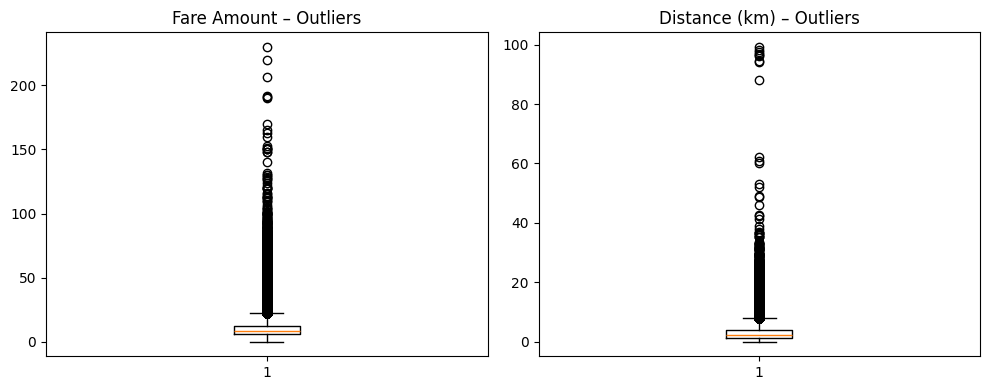

After outlier removal: (175556, 10)


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].boxplot(df['fare_amount'])
axes[0].set_title('Fare Amount – Outliers')
axes[1].boxplot(df['distance_km'])
axes[1].set_title('Distance (km) – Outliers')
plt.tight_layout()
plt.show()

# Remove fare outliers using IQR
Q1, Q3 = df['fare_amount'].quantile([0.25, 0.75])
IQR = Q3 - Q1
df = df[df['fare_amount'].between(Q1 - 1.5*IQR, Q3 + 1.5*IQR)]
print('After outlier removal:', df.shape)

## 3. Correlation

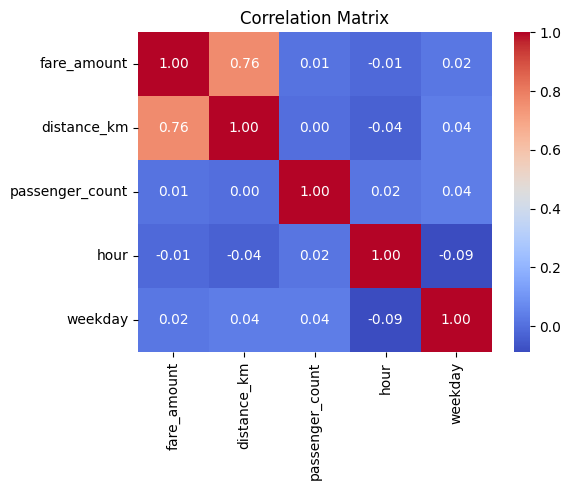

In [6]:
num_cols = ['fare_amount', 'distance_km', 'passenger_count', 'hour', 'weekday']
corr = df[num_cols].corr()

plt.figure(figsize=(6, 5))
import seaborn as sns
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

## 4. Model Training

In [7]:
feature_cols = ['distance_km', 'passenger_count', 'hour', 'weekday']
X = df[feature_cols].values
y = df['fare_amount'].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)

In [8]:
models = {
    'Linear Regression': LinearRegression(),
    'Ridge (α=1)':       Ridge(alpha=1.0),
    'Lasso (α=0.1)':     Lasso(alpha=0.1)
}

results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    r2   = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    results[name] = {'R²': round(r2, 4), 'RMSE': round(rmse, 4)}
    print(f'{name:25s}  R²={r2:.4f}  RMSE={rmse:.4f}')

pd.DataFrame(results).T

Linear Regression          R²=0.5759  RMSE=2.6788
Ridge (α=1)                R²=0.5759  RMSE=2.6788
Lasso (α=0.1)              R²=0.5754  RMSE=2.6804


,R²,RMSE
Linear Regression,0.5759,2.6788
Ridge (α=1),0.5759,2.6788
Lasso (α=0.1),0.5754,2.6804


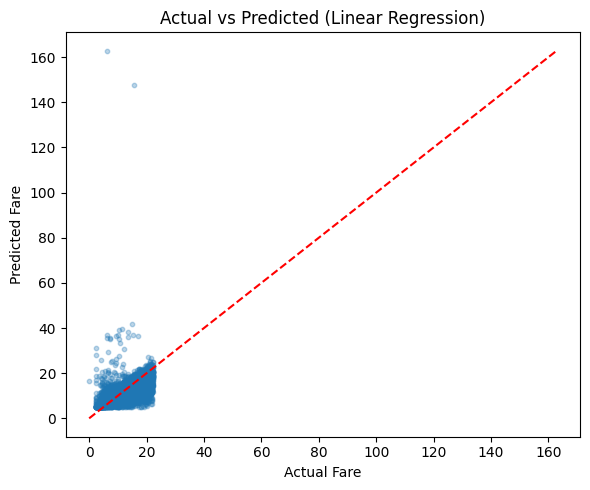

In [9]:
# Actual vs Predicted – Linear Regression
lr = models['Linear Regression']
y_pred_lr = lr.predict(X_test)

plt.figure(figsize=(6, 5))
plt.scatter(y_test, y_pred_lr, alpha=0.3, s=10)
lim = max(y_test.max(), y_pred_lr.max())
plt.plot([0, lim], [0, lim], 'r--')
plt.xlabel('Actual Fare')
plt.ylabel('Predicted Fare')
plt.title('Actual vs Predicted (Linear Regression)')
plt.tight_layout()
plt.show()